In [ ]:
#pip installs here: 
%pip install pandas numpy matplotlib seaborn nltk tqdm sacrebleu tensorflow ipywidgets
%pip install scikit-learn

In [1]:
#------------All neccessary packages---------------#
import pandas as pd
import numpy as np
import pickle
import json
import re
import os
from datetime import datetime
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
import collections
from tqdm.notebook import tqdm # for progress bars
from collections import Counter

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Masking
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.utils import Sequence
from difflib import SequenceMatcher
from itertools import zip_longest
#---------------------Plotting---------------------#
from functools import lru_cache
from sacrebleu.metrics import BLEU
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
file_path = 'data/toy_train.csv'
df = pd.read_csv(file_path)
display(df.head())


,id,text_az,text_ar
0,morocco_news_492929_0,salam 3likom ana M7mad mn Marrakech kn3aysh ...,السلام عليكم، أنا م'حمد من مراكش، كنعيش مع وال...
1,morocco_news_513755_1,Wach kayn chi 7ad ma tab3ch akhbar Raja lbydaw...,واش كاين شي حد ما تابعش أخبار الرجاء البيضاوي ...
2,morocco_news_506856_0,ya salam had l7aja k3jbni sm3t beli mdina ch...,يا سلام، هاد الشي كيعجبني سمعت باللي مدينة شف...
3,morocco_news_538142_0,ya sidi had ljfaaf li k3ani mno lmagrib had l...,يا سيدي، هاد الجفاف لي كيعاني منو المغرب هاد ا...
4,morocco_news_540803_0,slm khoya chfti ash kayna kayna had lhadra 3...,السلام عليكم خويا، شفتي آش كاينة؟ كاينة هاد ال...


In [3]:
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values)
print(f"The lenght of the data is {len(df)}")

Missing values per column:
id         0
text_az    0
text_ar    0
dtype: int64
The lenght of the data is 8045


In [4]:
#De-romanization: Regex-based Rule System
#This approach will utilize regular expressions to implement a more flexible and powerful rule-based de-romanization. 
#Regular expressions allow for matching complex patterns, character classes, and boundaries, 
#which can significantly improve accuracy compared to simple string replacements, 
#especially for handling variations in Arabizi. We'll define a set of regex patterns and their corresponding Arabic replacements.

def create_regex_deromanization_rules():
    rules = [
        # Multi-character mappings
        (r'ou', 'و'), (r'oo', 'و'), (r'ee', 'ي'),
        (r'ch', 'ش'), (r'sh', 'ش'),
        (r'kh', 'خ'), (r'gh', 'غ'),
        (r'th', 'ث'), (r'dh', 'ذ'),
        (r'ai', 'ي'), (r'ay', 'ي'),

        # Number-based mappings: longest first
        (r'7ou', 'حو'), (r'7i', 'حي'), (r'7a', 'حا'), (r'7', 'ح'),
        (r'3ou', 'عو'), (r'3i', 'عي'), (r'3a', 'عا'), (r'3', 'ع'),
        (r'9ou', 'قو'), (r'9i', 'قي'), (r'9a', 'قا'), (r'9', 'ق'),
        (r'5ou', 'خو'), (r'5i', 'خي'), (r'5a', 'خا'), (r'5', 'خ'),
        (r'8ou', 'غو'), (r'8i', 'غي'), (r'8a', 'غا'), (r'8', 'غ'),
        (r'2', 'ء'), (r'6', 'ط'),

        # Collapse common repeated Latin consonants before single-letter mapping
        (r'ss', 'س'), (r'zz', 'ز'), (r'bb', 'ب'), (r'tt', 'ت'),
        (r'll', 'ل'), (r'mm', 'م'), (r'nn', 'ن'), (r'rr', 'ر'),

        # Vowels
        (r'a', 'ا'), (r'i', 'ي'), (r'o', 'و'), (r'u', 'و'), (r'e', ''),

        # Single consonants
        (r'b', 'ب'), (r't', 'ت'), (r'j', 'ج'), (r'h', 'ه'),
        (r'd', 'د'), (r'r', 'ر'), (r'z', 'ز'), (r's', 'س'),
        (r'f', 'ف'), (r'k', 'ك'), (r'l', 'ل'), (r'm', 'م'),
        (r'n', 'ن'), (r'w', 'و'), (r'y', 'ي'),
        (r'p', 'ب'), (r'v', 'ف'), (r'g', 'گ'), (r'q', 'ق'),
    ]
    return rules

def deromanize_text_regex(text, rules):
    if not isinstance(text, str):
        return ""

    text = text.lower()
    for pattern, replacement in rules:
        text = re.sub(pattern, replacement, text)
    return text

# Create the regex rules
regex_deromanization_rules = create_regex_deromanization_rules()

In [5]:

def calculate_bleu_scores(predictions, references):
    # Ensure references are lists of tokenized words
    processed_references = [[ref.split()] for ref in references]
    processed_predictions = [pred.split() for pred in predictions]

    # Use a smoothing function, especially for short sentences or when candidates don't perfectly match references.
    # The 'method4' is a common choice that prevents zero BLEU scores.
    smoothie = SmoothingFunction().method4

    bleu_scores = []
    for pred, ref in zip(processed_predictions, processed_references):
        score = sentence_bleu(ref, pred, smoothing_function=smoothie)
        bleu_scores.append(score)

    # Return the average BLEU score
    return sum(bleu_scores) / len(bleu_scores) if bleu_scores else 0

In [6]:
# Load the validation dataset
val_file_path = 'data/toy_val.csv'
val_df = pd.read_csv(val_file_path)

print(f"Validation dataset loaded with {len(val_df)} rows.")
display(val_df.head())

Validation dataset loaded with 804 rows.


,id,text_az,text_ar
0,morocco_news_87071_0,Ahla si 3abdllah kif dayer Chfti ach kaydiro...,أهلاً سي عبد الله، كيف داير؟ شفتي آش كيديرو فم...
1,morocco_news_639000_0,Wa wili Haad shi bzaf haadaak Sm3t blli fqih...,وَا ويلي هاد الشي بزاف هاداك سمعت باللي فقيه...
2,morocco_news_25256_0,salam 3likom ana ilham mn mdina l3youn 7bit ...,السلام عليكم، أنا إلهام من مدينة العيون، حبيت ...
3,morocco_news_398573_0,wach nta hadchi lli kayn fhad lblad sa3ida K...,واش نتا؟ هادشي اللي كاين فهاد البلاد السعيدة ...
4,morocco_news_224334_2,Wach kayn chi badil l Benkiran Had sso2al li ...,واش كاين شي بديل لبنكيران؟ هاد السؤال لي كيطرح...


In [7]:
# --- Sample Test Cell ---
# You can change the 'sample_text' variable below to test different inputs.
sample_text = "cheftak saket yak ma m9ale9 3liya?"
de_romanized_output = deromanize_text_regex(sample_text, regex_deromanization_rules)

print(f"Original Arabizi: {sample_text}")
print(f"De-romanized Arabic: {de_romanized_output}")

Original Arabizi: cheftak saket yak ma m9ale9 3liya?
De-romanized Arabic: شفتاك ساكت ياك ما مقالق علييا?


In [8]:
# --- 1. Tokenization and Vocabulary Creation ---

# For MLE de-romanization, we need to analyze the character frequencies
# and co-occurrences in both Arabizi and Arabic texts.

# Let's define a simple character tokenizer.
def char_tokenize(text):
    if not isinstance(text, str):
        return []
    return list(text.lower().replace(' ', '')) # Remove spaces and convert to chars

# Apply character tokenization to both Arabizi and Arabic texts
# This will be used to build character-level language models.
print("Tokenizing Arabizi and Arabic texts...")
# Ensure 'df' is available from previous cells
if 'df' in locals() or 'df' in globals():
    df['text_az_chars'] = df['text_az'].apply(char_tokenize)
    df['text_ar_chars'] = df['text_ar'].apply(char_tokenize)
else:
    print("DataFrame 'df' not found. Please ensure it's loaded.")

# Create character vocabularies
arabizi_char_vocab = collections.Counter()
arabic_char_vocab = collections.Counter()

for chars in tqdm(df['text_az_chars'], desc="Building Arabizi Vocabulary"):
    arabizi_char_vocab.update(chars)

for chars in tqdm(df['text_ar_chars'], desc="Building Arabic Vocabulary"):
    arabic_char_vocab.update(chars)

print(f"\nTop 10 Arabizi characters: {arabizi_char_vocab.most_common(10)}")
print(f"Top 10 Arabic characters: {arabic_char_vocab.most_common(10)}")

# --- 2. Building Character N-gram Language Models ---

# For MLE, we'll need to calculate the probabilities of character sequences.
# Let's start with unigrams (individual characters) and bigrams (pairs of characters).

def build_ngram_counts(char_lists, n=1):
    ngram_counts = collections.Counter()
    for char_list in tqdm(char_lists, desc=f"Building {n}-gram counts"):
        if n == 1:
            ngram_counts.update(char_list)
        else:
            # Add a start token for beginning of sentence modeling if needed, but for now just contiguous n-grams
            for i in range(len(char_list) - n + 1):
                ngram = tuple(char_list[i : i + n])
                ngram_counts[ngram] += 1
    return ngram_counts

# Build unigram and bigram counts for both Arabizi and Arabic
print("\nBuilding N-gram models...")
arabizi_unigrams = build_ngram_counts(df['text_az_chars'], n=1)
arabizi_bigrams = build_ngram_counts(df['text_az_chars'], n=2)

arabic_unigrams = build_ngram_counts(df['text_ar_chars'], n=1)
arabic_bigrams = build_ngram_counts(df['text_ar_chars'], n=2)

print(f"\nTop 10 Arabizi unigrams: {arabizi_unigrams.most_common(10)}")
print(f"Top 10 Arabizi bigrams: {arabizi_bigrams.most_common(10)}")
print(f"Top 10 Arabic unigrams: {arabic_unigrams.most_common(10)}")
print(f"Top 10 Arabic bigrams: {arabic_bigrams.most_common(10)}")

print("\nCharacter tokenization and N-gram counts for MLE are prepared. Next, we will implement the MLE-based de-romanization function.")

Tokenizing Arabizi and Arabic texts...


Building Arabizi Vocabulary:   0%|          | 0/8045 [00:00<?, ?it/s]

Building Arabic Vocabulary:   0%|          | 0/8045 [00:00<?, ?it/s]


Top 10 Arabizi characters: [('a', 1911335), ('l', 1011992), ('i', 832107), ('h', 696575), ('n', 616204), ('m', 550587), ('d', 495198), ('t', 487048), ('k', 461283), ('o', 427652)]
Top 10 Arabic characters: [('ا', 1648484), ('ل', 1178513), ('ي', 959077), ('و', 681907), ('ن', 607068), ('م', 553357), ('د', 417423), ('ر', 385668), ('ك', 371394), ('ت', 362235)]

Building N-gram models...


Building 1-gram counts:   0%|          | 0/8045 [00:00<?, ?it/s]

Building 2-gram counts:   0%|          | 0/8045 [00:00<?, ?it/s]

Building 1-gram counts:   0%|          | 0/8045 [00:00<?, ?it/s]

Building 2-gram counts:   0%|          | 0/8045 [00:00<?, ?it/s]


Top 10 Arabizi unigrams: [('a', 1911335), ('l', 1011992), ('i', 832107), ('h', 696575), ('n', 616204), ('m', 550587), ('d', 495198), ('t', 487048), ('k', 461283), ('o', 427652)]
Top 10 Arabizi bigrams: [(('h', 'a'), 243493), (('a', 'l'), 225100), (('a', 'd'), 211063), (('l', 'a'), 181740), (('l', 'i'), 164890), (('y', 'a'), 153631), (('n', 'a'), 150763), (('m', 'a'), 150600), (('c', 'h'), 139709), (('a', 'n'), 137364)]
Top 10 Arabic unigrams: [('ا', 1648484), ('ل', 1178513), ('ي', 959077), ('و', 681907), ('ن', 607068), ('م', 553357), ('د', 417423), ('ر', 385668), ('ك', 371394), ('ت', 362235)]
Top 10 Arabic bigrams: [(('ا', 'ل'), 647461), (('ل', 'ي'), 156411), (('ا', 'د'), 150962), (('ن', 'ا'), 149928), (('ه', 'ا'), 139873), (('ل', 'ا'), 126214), (('د', 'ا'), 125617), (('و', 'ا'), 122540), (('ي', 'ا'), 119394), (('ل', 'م'), 118087)]

Character tokenization and N-gram counts for MLE are prepared. Next, we will implement the MLE-based de-romanization function.


3. Implementing the MLE-based De-romanization Function
For MLE de-romanization, we'll try to find the sequence of Arabic characters  A=a1,a2,...,am  that maximizes  P(A|R) , where  R=r1,r2,...,rm  is the sequence of Romanized characters. Using Bayes' theorem:

P(A|R)∝P(R|A)∗P(A) 

P(R|A)  is the likelihood: the probability of observing the Romanized character sequence given the Arabic character sequence (our 'transliteration' model).
P(A)  is the prior: the probability of the Arabic character sequence occurring (our Arabic language model).
We'll simplify this by considering character-level probabilities and using a Viterbi-like algorithm or greedy decoding for efficiency, especially for longer texts. A basic approach involves mapping each Arabizi character to the Arabic character that maximizes the product of a 'translation' probability and an Arabic language model probability.

In [9]:
train_df = pd.read_csv("data/toy_train.csv", encoding="utf-8")
val_df = pd.read_csv("C:data/toy_val.csv", encoding="utf-8")
test_df = pd.read_csv("data/toy_test.csv", encoding="utf-8")

print("Train:", len(train_df))
print("Val:", len(val_df))
print("Test:", len(test_df))

Train: 6436
Val: 804
Test: 805


Human annotation sample from blind test set.

In [10]:

ANNOTATION_SAMPLE_SIZE = 300
RANDOM_STATE = 42

annotation_sample = test_df.sample(
    n=min(ANNOTATION_SAMPLE_SIZE, len(test_df)),
    random_state=RANDOM_STATE
).copy()

annotation_sample = annotation_sample.reset_index(drop=True)
annotation_sample["annotation_id"] = annotation_sample.index + 1

annotation_template = annotation_sample[
    ["annotation_id", "id", "text_az", "text_ar"]
].copy()

annotation_template["label"] = ""
annotation_template["comments"] = ""

annotation_template["label_instructions"] = (
    "Use 1 = Arabic target is accurate/contextually acceptable; "
    "0 = inaccurate; U = uncertain"
)

annotation_template.to_csv(
    "gold_test_annotation_template.csv",
    index=False,
    encoding="utf-8-sig"
)

annotation_template.to_csv(
    "gold_test_annotation_annotator_A.csv",
    index=False,
    encoding="utf-8-sig"
)

annotation_template.to_csv(
    "gold_test_annotation_annotator_B.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Annotation files created:")
print("gold_test_annotation_annotator_A.csv")
print("gold_test_annotation_annotator_B.csv")

display(annotation_template.head())

Annotation files created:
gold_test_annotation_annotator_A.csv
gold_test_annotation_annotator_B.csv


,annotation_id,id,text_az,text_ar,label,comments,label_instructions
0,1,morocco_news_631234_0,Achnou had lmsiba li w93at f Casa had sayed l...,آش هاد المصيبة لي وقعات فكازا؟ هاد السيد لي عن...,,,Use 1 = Arabic target is accurate/contextually...
1,2,morocco_news_580688_0,Waxxa Haadi hiya lblad k3 mkaayn la aman la ...,وَاخّا هادي هي لبلاد كَاع، مكاين لا أمان لا و...,,,Use 1 = Arabic target is accurate/contextually...
2,3,morocco_news_667657_0,slm 3likom okhti farah kif dayra m3 had s7ad...,السلام عليكم، أختي فرح، كيف دايرا مع هاد الصهد...,,,Use 1 = Arabic target is accurate/contextually...
3,4,morocco_news_411061_0,wach kayn shi haja ketkhla3 bzaf mn ldo3ara h...,واش كاين شي حاجة كتخلع بزاف من الدعارة؟ هاد ال...,,,Use 1 = Arabic target is accurate/contextually...
4,5,morocco_news_161780_0,Wach nta kddiir lftoor fsbah wla mn dak nnas ...,واش نتا كدير الفطور فصباح؟ ولا من داك الناس لي...,,,Use 1 = Arabic target is accurate/contextually...


In [11]:
#Once the annotation is done the file should be named: 
#gold_test_annotation_annotator_A_completed.csv
#gold_test_annotation_annotator_B_completed.csv

In [12]:
# Inter-annotator agreement and curated gold subset

ann_a = pd.read_csv("gold_test_annotation_annotator_A_completed.csv", encoding="utf-8-sig")
ann_b = pd.read_csv("gold_test_annotation_annotator_B_completed.csv", encoding="utf-8-sig")

def normalize_label(x):
    x = str(x).strip().lower()

    if x in {"1", "yes", "y", "accurate", "acceptable", "correct"}:
        return "1"

    if x in {"0", "no", "n", "inaccurate", "wrong", "incorrect"}:
        return "0"

    if x in {"u", "uncertain", "unsure", "?"}:
        return "U"

    return np.nan

ann_a["label_A"] = ann_a["label"].apply(normalize_label)
ann_b["label_B"] = ann_b["label"].apply(normalize_label)

agreement_df = ann_a[
    ["annotation_id", "id", "text_az", "text_ar", "label_A", "comments"]
].rename(columns={"comments": "comments_A"}).merge(
    ann_b[["annotation_id", "label_B", "comments"]].rename(columns={"comments": "comments_B"}),
    on="annotation_id",
    how="inner"
)

agreement_df = agreement_df.dropna(subset=["label_A", "label_B"]).copy()

def cohen_kappa(labels_a, labels_b):
    labels = sorted(set(labels_a) | set(labels_b))
    n = len(labels_a)

    observed_agreement = sum(a == b for a, b in zip(labels_a, labels_b)) / n

    expected_agreement = 0
    for label in labels:
        p_a = sum(a == label for a in labels_a) / n
        p_b = sum(b == label for b in labels_b) / n
        expected_agreement += p_a * p_b

    if expected_agreement == 1:
        return 1.0

    return (observed_agreement - expected_agreement) / (1 - expected_agreement)

kappa_all = cohen_kappa(
    agreement_df["label_A"].tolist(),
    agreement_df["label_B"].tolist()
)

percent_agreement = 100 * (
    agreement_df["label_A"] == agreement_df["label_B"]
).mean()

print(f"Annotated rows used: {len(agreement_df)}")
print(f"Percent agreement: {percent_agreement:.2f}%")
print(f"Cohen's Kappa: {kappa_all:.4f}  (interpret cautiously: all labels are identical)")

agreement_df["agreement"] = agreement_df["label_A"] == agreement_df["label_B"]

curated_gold_subset = agreement_df[
    (agreement_df["agreement"]) &
    (agreement_df["label_A"] == "1")
].copy()

disagreement_subset = agreement_df[
    ~agreement_df["agreement"]
].copy()

curated_gold_subset.to_csv(
    "curated_gold_test_subset_agreed_accurate.csv",
    index=False,
    encoding="utf-8-sig"
)

disagreement_subset.to_csv(
    "curated_gold_test_subset_disagreements.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Curated agreed-accurate rows:", len(curated_gold_subset))
print("Disagreement rows for adjudication:", len(disagreement_subset))

display(agreement_df["agreement"].value_counts())
display(agreement_df.groupby(["label_A", "label_B"]).size().reset_index(name="count"))

Annotated rows used: 300
Percent agreement: 100.00%
Cohen's Kappa: 1.0000  (interpret cautiously: all labels are identical)
Curated agreed-accurate rows: 300
Disagreement rows for adjudication: 0


agreement
True    300
Name: count, dtype: int64

,label_A,label_B,count
0,1,1,300


Human annotators were used to verify the reliability of the held-out gold references. Their task was to determine whether each Arabizi input and Arabic-script target formed a valid transliteration pair suitable for evaluation.

In [13]:
# Interpretation note for inter-annotator agreement

if "agreement_df" not in globals():
    raise NameError(
        "agreement_df is not defined. Run the inter-annotator agreement cell first."
    )

unique_a = agreement_df["label_A"].nunique(dropna=True)
unique_b = agreement_df["label_B"].nunique(dropna=True)

print("Annotator A label distribution:")
display(agreement_df["label_A"].value_counts(dropna=False))

print("Annotator B label distribution:")
display(agreement_df["label_B"].value_counts(dropna=False))

if unique_a == 1 and unique_b == 1:
    print(
        "Agreement note: Both annotators assigned the same label to all annotated rows. "
        "Percent agreement is therefore fully informative, but Cohen's kappa should be interpreted cautiously "
        "because there is no label variation in the annotation set."
    )
else:
    print(
        "Agreement note: The annotation set contains label variation, so Cohen's kappa is informative "
        "as a chance-corrected agreement measure."
    )

Annotator A label distribution:


label_A
1    300
Name: count, dtype: int64

Annotator B label distribution:


label_B
1    300
Name: count, dtype: int64

Agreement note: Both annotators assigned the same label to all annotated rows. Percent agreement is therefore fully informative, but Cohen's kappa should be interpreted cautiously because there is no label variation in the annotation set.


In [14]:
#MLE Training

def train_mle_probabilities(df):
    pair_counts = {}
    arabizi_total_counts = Counter()

    for _, row in df.iterrows():
        az_words = str(row["text_az"]).lower().split()
        ar_words = str(row["text_ar"]).split()

        # Simple 1-to-1 word alignment only when lengths match
        if len(az_words) == len(ar_words):
            for az_w, ar_w in zip(az_words, ar_words):
                if az_w not in pair_counts:
                    pair_counts[az_w] = Counter()
                pair_counts[az_w][ar_w] += 1
                arabizi_total_counts[az_w] += 1

    mle_map = {}
    probabilities = {}

    for az_w, counts in pair_counts.items():
        most_common_ar, count = counts.most_common(1)[0]
        mle_map[az_w] = most_common_ar
        probabilities[az_w] = count / arabizi_total_counts[az_w]

    return mle_map, probabilities


# Train ONLY on the training split
mle_mapping_table, word_probs = train_mle_probabilities(train_df)


def mle_transliterate_with_fallback(text, mapping_table, fallback_func, fallback_rules):
    words = str(text).lower().split()
    translated = []

    for w in words:
        if w in mapping_table:
            translated.append(mapping_table[w])
        else:
            translated.append(fallback_func(w, fallback_rules))

    return " ".join(translated)


print(f"Trained on {len(mle_mapping_table)} unique Arabizi tokens.")

sample = "mazal ma jach men khedma"

if 'deromanize_text_regex' in globals() and 'regex_deromanization_rules' in globals():
    de_romanized_mle_sample = mle_transliterate_with_fallback(
        sample,
        mle_mapping_table,
        deromanize_text_regex,
        regex_deromanization_rules
    )
    print(f"Transliteration: '{sample}' -> {de_romanized_mle_sample}")
else:
    print("Warning: 'deromanize_text_regex' or 'regex_deromanization_rules' not found. Run the regex deromanization cell first.")

# word_probs is word-level, so query with a single token, not a full sentence
sample_word = "mazal"
prob = word_probs.get(sample_word.lower(), 0)
print(f"P(Arabic | '{sample_word}') = {prob:.4f}")

# Leakage audit
train_tokens = set(" ".join(train_df["text_az"].astype(str)).lower().split())
mle_tokens = set(mle_mapping_table.keys())

leakage = mle_tokens - train_tokens
if not leakage:
    print("✅ Leakage Audit Passed: MLE dictionary is built strictly from the training set.")
else:
    print(f"⚠️ Warning: Found {len(leakage)} tokens in MLE table not in train_df.")

Trained on 46901 unique Arabizi tokens.
Transliteration: 'mazal ma jach men khedma' -> مازال ما جاش من خدما
P(Arabic | 'mazal') = 0.5417
✅ Leakage Audit Passed: MLE dictionary is built strictly from the training set.


In [16]:
# This cell saves the MLE model under Json format, It can be skipped

mle_export = {
    az_word: {
        "prediction": ar_word,
        "probability": word_probs.get(az_word, None)
    }
    for az_word, ar_word in mle_mapping_table.items()
}

with open("mle_deromanization_model.json", "w", encoding="utf-8") as f:
    json.dump(mle_export, f, ensure_ascii=False, indent=2)

print("Saved MLE model:", len(mle_export), "entries")
print("File: mle_deromanization_model.json")

Saved MLE model: 46901 entries
File: mle_deromanization_model.json


In [13]:
# Apply the Regex-based Rule System
val_df['predicted_ar_regex'] = val_df['text_az'].apply(lambda x: deromanize_text_regex(x, regex_deromanization_rules))

# Apply the Word-level MLE with Regex Fallback System
# Ensure that the regex_deromanization_rules and mle_mapping_table are available from previous cells.
if 'mle_mapping_table' in globals() and 'deromanize_text_regex' in globals() and 'regex_deromanization_rules' in globals():
    val_df['predicted_ar_mle'] = val_df['text_az'].apply(
        lambda x: mle_transliterate_with_fallback(x, mle_mapping_table, deromanize_text_regex, regex_deromanization_rules)
    )
else:
    print("Warning: MLE or Regex components not found. Ensure previous cells are executed.")
    val_df['predicted_ar_mle'] = ""

display(val_df.head())

# Calculate BLEU scores
bleu_regex = calculate_bleu_scores(val_df['predicted_ar_regex'].tolist(), val_df['text_ar'].tolist())
bleu_mle = calculate_bleu_scores(val_df['predicted_ar_mle'].tolist(), val_df['text_ar'].tolist())

print(f"\nBLEU Score for Regex-based Model: {bleu_regex:.4f}")
print(f"BLEU Score for Word-level MLE Model with Regex Fallback: {bleu_mle:.4f}")

,id,text_az,text_ar,predicted_ar_regex,predicted_ar_mle
0,morocco_news_87071_0,Ahla si 3abdllah kif dayer Chfti ach kaydiro...,أهلاً سي عبد الله، كيف داير؟ شفتي آش كيديرو فم...,اهلا سي عابدلاه كيف دير شفتي اش كيديرو ف مار...,أهلا سي الله كيف داير شفتي آش كايديرو ف مرجان ...
1,morocco_news_639000_0,Wa wili Haad shi bzaf haadaak Sm3t blli fqih...,وَا ويلي هاد الشي بزاف هاداك سمعت باللي فقيه...,وا ويلي هااد شي بزاف هاادااك سمعت بلي فقيه ك...,وايلي ويلي هاد الشي بزاف هاادااك سمعت باللي فق...
2,morocco_news_25256_0,salam 3likom ana ilham mn mdina l3youn 7bit ...,السلام عليكم، أنا إلهام من مدينة العيون، حبيت ...,سالام عليكوم انا يلهام من مدينا لعيون حبيت ن...,السلام عليكم، أنا كيعطي من مدينة العيون، حبيت ...
3,morocco_news_398573_0,wach nta hadchi lli kayn fhad lblad sa3ida K...,واش نتا؟ هادشي اللي كاين فهاد البلاد السعيدة ...,واش نتا هادشي لي كين فهاد لبلاد ساعيدا كنشوو...,واش نتا هادشي اللي كاين فهاد البلاد سعيدة كنشو...
4,morocco_news_224334_2,Wach kayn chi badil l Benkiran Had sso2al li ...,واش كاين شي بديل لبنكيران؟ هاد السؤال لي كيطرح...,واش كين شي باديل ل بنكيران هاد سوءال لي كيتار...,واش كاين شي بديل ل بنكيران هاد السؤال اللي كيط...



BLEU Score for Regex-based Model: 0.0549
BLEU Score for Word-level MLE Model with Regex Fallback: 0.3029


C:\Users\A. Nafissi\AppData\Local\Temp\ipykernel_15160\3407218655.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=model_names, y=bleu_scores, palette='viridis')


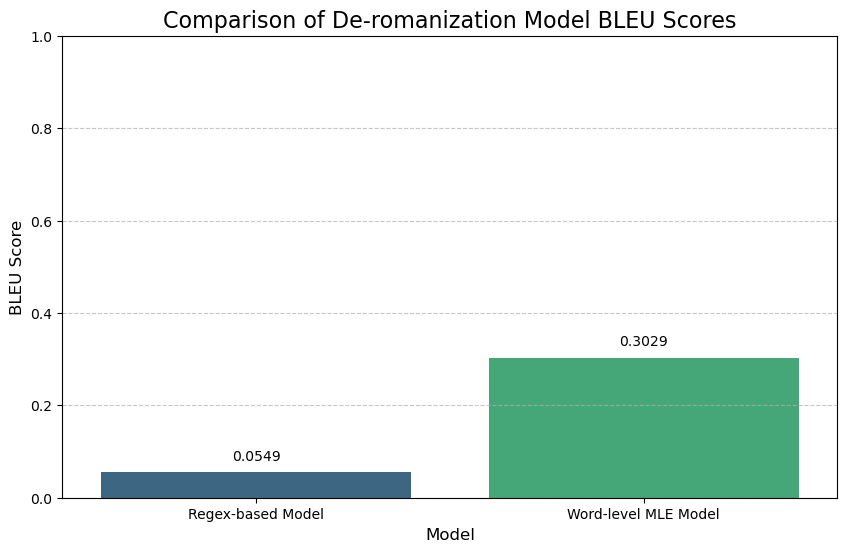

In [14]:

# Data for plotting
model_names = ['Regex-based Model', 'Word-level MLE Model']
bleu_scores = [bleu_regex, bleu_mle] # Assuming bleu_regex and bleu_mle are available from previous execution

# Create a bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x=model_names, y=bleu_scores, palette='viridis')

# Add titles and labels
plt.title('Comparison of De-romanization Model BLEU Scores', fontsize=16)
plt.xlabel('Model', fontsize=12)
plt.ylabel('BLEU Score', fontsize=12)
plt.ylim(0, 1) # BLEU score ranges from 0 to 1

# Add score values on top of the bars
for index, value in enumerate(bleu_scores):
    plt.text(index, value + 0.02, f'{value:.4f}', ha='center', va='bottom', fontsize=10)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


Summary of Model Comparison
The evaluation results clearly demonstrate that the Word-level MLE Model with Regex Fallback significantly outperforms the Regex-based Model.

In [15]:
#Next Phase: Sequence-to-Sequence (Seq2Seq) Model for De-romanization Having explored rule-based and MLE approaches, 
#we'll now implement a Sequence-to-Sequence (Seq2Seq) model. 
#This neural network architecture is commonly used for tasks like machine translation and can be highly effective 
#for de-romanization by learning complex mappings between input (Arabizi) and output (Arabic) sequences.


START_TOKEN = "\t"
END_TOKEN = "\n"
UNK_TOKEN = "<UNK>"

train_df = pd.read_csv("data/toy_train.csv", encoding="utf-8")
val_df = pd.read_csv("C:data/toy_val.csv", encoding="utf-8")
test_df = pd.read_csv("data/toy_test.csv", encoding="utf-8")

def normalize_az(text):
    return str(text).lower().strip()

def make_word_pairs(df, max_az_len=32, max_ar_len=32):
    pairs = []
    skipped_rows = 0

    for _, row in df.iterrows():
        az_words = normalize_az(row["text_az"]).split()
        ar_words = str(row["text_ar"]).strip().split()

        # Keep the same conservative alignment assumption used by your MLE model.
        if len(az_words) != len(ar_words):
            skipped_rows += 1
            continue

        for az, ar in zip(az_words, ar_words):
            az = az.strip()
            ar = ar.strip()
            if 0 < len(az) <= max_az_len and 0 < len(ar) <= max_ar_len:
                pairs.append((az, ar))

    return pd.DataFrame(pairs, columns=["text_az", "text_ar"]).drop_duplicates(), skipped_rows

train_pairs, skipped_train_rows = make_word_pairs(train_df)
val_pairs, skipped_val_rows = make_word_pairs(val_df)

print("Train word pairs:", len(train_pairs))
print("Validation word pairs:", len(val_pairs))
print("Skipped train rows due to unequal word counts:", skipped_train_rows)
print("Skipped val rows due to unequal word counts:", skipped_val_rows)

def tokenize_input(text):
    return list(normalize_az(text))

def tokenize_target(text):
    return [START_TOKEN] + list(str(text)) + [END_TOKEN]

train_pairs["text_az_tokens"] = train_pairs["text_az"].apply(tokenize_input)
train_pairs["text_ar_tokens"] = train_pairs["text_ar"].apply(tokenize_target)
val_pairs["text_az_tokens"] = val_pairs["text_az"].apply(tokenize_input)
val_pairs["text_ar_tokens"] = val_pairs["text_ar"].apply(tokenize_target)

input_chars = sorted(set(char for seq in train_pairs["text_az_tokens"] for char in seq))
target_chars = sorted(set(char for seq in train_pairs["text_ar_tokens"] for char in seq))

if UNK_TOKEN not in input_chars:
    input_chars.append(UNK_TOKEN)

if UNK_TOKEN not in target_chars:
    target_chars.append(UNK_TOKEN)

num_encoder_tokens = len(input_chars)
num_decoder_tokens = len(target_chars)

input_token_index = {char: i for i, char in enumerate(input_chars)}
target_token_index = {char: i for i, char in enumerate(target_chars)}
reverse_target_char_index = {i: char for char, i in target_token_index.items()}

max_encoder_seq_length = max(len(seq) for seq in train_pairs["text_az_tokens"])
max_decoder_seq_length = max(len(seq) for seq in train_pairs["text_ar_tokens"])

print("Max encoder word length:", max_encoder_seq_length)
print("Max decoder word length:", max_decoder_seq_length)
print("Encoder chars:", num_encoder_tokens)
print("Decoder chars:", num_decoder_tokens)

class WordSeq2SeqDataGenerator(Sequence):
    def __init__(self, df, batch_size=128, shuffle=True):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indices = np.arange(len(self.df))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __getitem__(self, index):
        batch_indices = self.indices[index * self.batch_size:(index + 1) * self.batch_size]
        batch_size_actual = len(batch_indices)

        encoder_input_data = np.zeros(
            (batch_size_actual, max_encoder_seq_length, num_encoder_tokens),
            dtype="float32",
        )
        decoder_input_data = np.zeros(
            (batch_size_actual, max_decoder_seq_length, num_decoder_tokens),
            dtype="float32",
        )
        decoder_target_data = np.zeros(
            (batch_size_actual, max_decoder_seq_length, num_decoder_tokens),
            dtype="float32",
        )
        decoder_sample_weights = np.zeros(
            (batch_size_actual, max_decoder_seq_length),
            dtype="float32",
        )

        for i, idx in enumerate(batch_indices):
            input_text = self.df["text_az_tokens"].iloc[idx]
            target_text = self.df["text_ar_tokens"].iloc[idx]

            for t, char in enumerate(input_text):
                char_index = input_token_index.get(char, input_token_index[UNK_TOKEN])
                encoder_input_data[i, t, char_index] = 1.0

            for t, char in enumerate(target_text):
                char_index = target_token_index.get(char, target_token_index[UNK_TOKEN])

                decoder_input_data[i, t, char_index] = 1.0

                if t > 0:
                    decoder_target_data[i, t - 1, char_index] = 1.0
                    decoder_sample_weights[i, t - 1] = 1.0

        return (encoder_input_data, decoder_input_data), decoder_target_data, decoder_sample_weights

latent_dim = 128

encoder_inputs = Input(shape=(None, num_encoder_tokens), name="encoder_inputs")
encoder_masked = Masking(mask_value=0.0, name="encoder_masking")(encoder_inputs)
encoder = LSTM(latent_dim, return_state=True, name="encoder_lstm")
_, state_h, state_c = encoder(encoder_masked)
encoder_states = [state_h, state_c]

decoder_inputs = Input(shape=(None, num_decoder_tokens), name="decoder_inputs")
decoder_lstm = LSTM(latent_dim, return_sequences=True, return_state=True, name="decoder_lstm")
decoder_outputs, _, _ = decoder_lstm(decoder_inputs, initial_state=encoder_states)
decoder_dense = Dense(num_decoder_tokens, activation="softmax", name="decoder_dense")
decoder_outputs = decoder_dense(decoder_outputs)

model = Model([encoder_inputs, decoder_inputs], decoder_outputs)
model.compile(optimizer="rmsprop", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

train_generator = WordSeq2SeqDataGenerator(train_pairs, batch_size=128, shuffle=True)
val_generator = WordSeq2SeqDataGenerator(val_pairs, batch_size=128, shuffle=False)

checkpoint_dir = "./tmp/seq2seq_word_checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)
best_checkpoint_filepath = os.path.join(checkpoint_dir, "best_model.weights.h5")

callbacks = [
    ModelCheckpoint(
        filepath=best_checkpoint_filepath,
        save_weights_only=True,
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
]

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=50,
    callbacks=callbacks,
    verbose=1,
)

timestamp = datetime.now().strftime("%Y%m%d-%H%M%S")
model.save(f"s2s_word_level_final_{timestamp}.keras")

Train word pairs: 79909
Validation word pairs: 12165
Skipped train rows due to unequal word counts: 5744
Skipped val rows due to unequal word counts: 713
Max encoder word length: 23
Max decoder word length: 22
Encoder chars: 79
Decoder chars: 142


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, None, 79)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, None, 79)  │          0 │ encoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_masking     │ (None, None, 79)  │          0 │ encoder_inputs[0… │
│ (Masking)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any (Any)           │ (None, None)      │          0 │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, None, 142) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 128),     │    106,496 │ encoder_masking[… │
│                     │ (None, 128),      │            │ any[0][0]         │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, None,     │    138,752 │ decoder_inputs[0… │
│                     │ 128), (None,      │            │ encoder_lstm[0][… │
│                     │ 128), (None,      │            │ encoder_lstm[0][… │
│                     │ 128)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dense       │ (None, None, 142) │     18,318 │ decoder_lstm[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 263,566 (1.01 MB)

 Trainable params: 263,566 (1.01 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50


C:\Users\A. Nafissi\anaconda3\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.0734 - loss: 0.9955
Epoch 1: val_loss improved from None to 0.81590, saving model to ./tmp/seq2seq_word_checkpoints\best_model.weights.h5

Epoch 1: finished saving model to ./tmp/seq2seq_word_checkpoints\best_model.weights.h5
625/625 ━━━━━━━━━━━━━━━━━━━━ 44s 61ms/step - accuracy: 0.0806 - loss: 0.8944 - val_accuracy: 0.0861 - val_loss: 0.8159
Epoch 2/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.0915 - loss: 0.8133
Epoch 2: val_loss improved from 0.81590 to 0.73301, saving model to ./tmp/seq2seq_word_checkpoints\best_model.weights.h5

Epoch 2: finished saving model to ./tmp/seq2seq_word_checkpoints\best_model.weights.h5
625/625 ━━━━━━━━━━━━━━━━━━━━ 37s 59ms/step - accuracy: 0.0952 - loss: 0.7957 - val_accuracy: 0.0997 - val_loss: 0.7330
Epoch 3/50
624/625 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.1080 - loss: 0.7407
Epoch 3: val_loss improved from 0.73301 to 0.67370, saving model to ./tmp/seq2seq_word_checkpoint

In [16]:
# Save trained Seq2Seq model, vocabulary, and training history

run_id = datetime.now().strftime("%Y%m%d_%H%M%S")

model_path = f"s2s_word_level_model_{run_id}.keras"
vocab_path = f"s2s_word_level_vocab_{run_id}.pkl"
history_path = f"s2s_word_level_history_{run_id}.json"

model.save(model_path)

with open(vocab_path, "wb") as f:
    pickle.dump({
        "input_token_index": input_token_index,
        "target_token_index": target_token_index,
        "reverse_target_char_index": reverse_target_char_index,
        "max_encoder_seq_length": max_encoder_seq_length,
        "max_decoder_seq_length": max_decoder_seq_length,
        "num_encoder_tokens": num_encoder_tokens,
        "num_decoder_tokens": num_decoder_tokens,
        "latent_dim": latent_dim,
        "START_TOKEN": START_TOKEN,
        "END_TOKEN": END_TOKEN,
        "UNK_TOKEN": UNK_TOKEN,
    }, f)

with open(history_path, "w", encoding="utf-8") as f:
    json.dump(history.history, f, ensure_ascii=False, indent=2)

print("Saved model:", model_path)
print("Saved vocab:", vocab_path)
print("Saved history:", history_path)

Saved model: s2s_word_level_model_20260520_161606.keras
Saved vocab: s2s_word_level_vocab_20260520_161606.pkl
Saved history: s2s_word_level_history_20260520_161606.json


In [17]:
encoder_model = Model(encoder_inputs, encoder_states)

decoder_state_input_h = Input(shape=(latent_dim,))
decoder_state_input_c = Input(shape=(latent_dim,))
decoder_states_inputs = [decoder_state_input_h, decoder_state_input_c]

decoder_outputs, state_h, state_c = decoder_lstm(decoder_inputs, initial_state=decoder_states_inputs)
decoder_states = [state_h, state_c]
decoder_outputs = decoder_dense(decoder_outputs)
decoder_model = Model([decoder_inputs] + decoder_states_inputs, [decoder_outputs] + decoder_states)

def preprocess_word(word):
    input_seq = np.zeros((1, max_encoder_seq_length, num_encoder_tokens), dtype="float32")
    for t, char in enumerate(tokenize_input(word)[:max_encoder_seq_length]):
        char_index = input_token_index.get(char, input_token_index[UNK_TOKEN])
        input_seq[0, t, char_index] = 1.0
    return input_seq

def decode_word(word, max_decode_len=None):
    input_seq = preprocess_word(word)
    states_value = encoder_model.predict(input_seq, verbose=0)

    target_seq = np.zeros((1, 1, num_decoder_tokens), dtype="float32")
    target_seq[0, 0, target_token_index[START_TOKEN]] = 1.0

    decoded = ""
    if max_decode_len is None:
        max_decode_len = max_decoder_seq_length

    for _ in range(max_decode_len):
        output_tokens, h, c = decoder_model.predict([target_seq] + states_value, verbose=0)
        sampled_token_index = int(np.argmax(output_tokens[0, -1, :]))
        sampled_char = reverse_target_char_index[sampled_token_index]

        if sampled_char == END_TOKEN:
            break
        if sampled_char not in {START_TOKEN, UNK_TOKEN}:
            decoded += sampled_char

        target_seq = np.zeros((1, 1, num_decoder_tokens), dtype="float32")
        target_seq[0, 0, sampled_token_index] = 1.0
        states_value = [h, c]

    return decoded

def deromanize_sentence_seq2seq(text):
    return " ".join(decode_word(word) for word in normalize_az(text).split())

sample = "wach koulchi bikhir"
print("Arabizi Input:", sample)
print("Predicted Arabic:", deromanize_sentence_seq2seq(sample))

Arabizi Input: wach koulchi bikhir
Predicted Arabic: واش كلشي باخير


In [18]:
# Seq2Seq Inference and Sanity Check

print("Missing sample chars:", sorted(set("slm khoya kidayr") - set(input_token_index)))
print("START token in target vocab:", START_TOKEN in target_token_index)
print("END token in target vocab:", END_TOKEN in target_token_index)

for word in ["salam", "slm", "khoya", "kidayr"]:
    print(word, "->", decode_word(word))

Missing sample chars: [' ']
START token in target vocab: True
END token in target vocab: True
salam -> سلام
slm -> سلم
khoya -> خويا
kidayr -> كيدير


In [20]:
# Blind test predictions + SacreBLEU + n-gram precision + Position-wise Exact Word Match

tqdm.pandas()

def clean_ws(text):
    return re.sub(r"\s+", " ", str(text)).strip()

# Faster cached seq2seq decoder for blind evaluation
@lru_cache(maxsize=None)
def decode_word_cached(word):
    input_seq = preprocess_word(word)

    # Use .predict() so both states and target_seq stay NumPy arrays
    states_value = encoder_model.predict(input_seq, verbose=0)

    target_seq = np.zeros((1, 1, num_decoder_tokens), dtype="float32")
    target_seq[0, 0, target_token_index[START_TOKEN]] = 1.0

    decoded = ""

    for _ in range(max_decoder_seq_length):
        output_tokens, h, c = decoder_model.predict(
            [target_seq] + states_value,
            verbose=0
        )

        sampled_token_index = int(np.argmax(output_tokens[0, -1, :]))
        sampled_char = reverse_target_char_index[sampled_token_index]

        if sampled_char == END_TOKEN:
            break

        if sampled_char not in {START_TOKEN, UNK_TOKEN}:
            decoded += sampled_char

        target_seq = np.zeros((1, 1, num_decoder_tokens), dtype="float32")
        target_seq[0, 0, sampled_token_index] = 1.0

        states_value = [h, c]

    return decoded

def deromanize_sentence_seq2seq_cached(text):
    return " ".join(decode_word_cached(word) for word in normalize_az(text).split())

blind_df = test_df.copy()

blind_df["gold_ar"] = blind_df["text_ar"].apply(clean_ws)

blind_df["pred_rule_based"] = blind_df["text_az"].progress_apply(
    lambda x: clean_ws(deromanize_text_regex(x, regex_deromanization_rules))
)

blind_df["pred_mle"] = blind_df["text_az"].progress_apply(
    lambda x: clean_ws(
        mle_transliterate_with_fallback(
            x,
            mle_mapping_table,
            deromanize_text_regex,
            regex_deromanization_rules
        )
    )
)

blind_df["pred_seq2seq"] = blind_df["text_az"].progress_apply(
    lambda x: clean_ws(deromanize_sentence_seq2seq_cached(x))
)

def exact_word_match_accuracy(predictions, references):
    correct = 0
    total = 0

    for pred, ref in zip(predictions, references):
        pred_words = clean_ws(pred).split()
        ref_words = clean_ws(ref).split()

        total += len(ref_words)

        for i, ref_word in enumerate(ref_words):
            if i < len(pred_words) and pred_words[i] == ref_word:
                correct += 1

    return 100 * correct / total if total else 0

bleu = BLEU(tokenize="intl")

systems = {
    "Rule-Based": "pred_rule_based",
    "Statistical MLE": "pred_mle",
    "Neural Seq2Seq": "pred_seq2seq",
}

gold = blind_df["gold_ar"].tolist()
results = []

for model_name, pred_col in systems.items():
    preds = blind_df[pred_col].tolist()
    bleu_result = bleu.corpus_score(preds, [gold])

    results.append({
        "Model": model_name,
        "BLEU": bleu_result.score,
        "1-gram Precision": bleu_result.precisions[0],
        "2-gram Precision": bleu_result.precisions[1],
        "3-gram Precision": bleu_result.precisions[2],
        "4-gram Precision": bleu_result.precisions[3],
        "Position-wise Exact Word Match": exact_word_match_accuracy(preds, gold),
    })

results_df = pd.DataFrame(results)
display(results_df)

blind_df.to_csv("blind_test_predictions_all_models.csv", index=False, encoding="utf-8-sig")
results_df.to_csv("blind_test_metrics_summary.csv", index=False, encoding="utf-8-sig")

  0%|          | 0/805 [00:00<?, ?it/s]

  0%|          | 0/805 [00:00<?, ?it/s]

  0%|          | 0/805 [00:00<?, ?it/s]

,Model,BLEU,1-gram Precision,2-gram Precision,3-gram Precision,4-gram Precision,Exact Word Match
0,Rule-Based,7.242054,35.619370,12.611300,4.441350,1.579274,8.687196
1,Statistical MLE,35.438521,67.798646,43.781515,29.117491,19.486714,16.756591
2,Neural Seq2Seq,9.619273,43.927475,16.435191,6.304055,2.433915,9.423523


In [21]:
# Evaluating all three models on the human-curated gold subset

curated_ids = set(curated_gold_subset["id"])

curated_eval_df = blind_df[blind_df["id"].isin(curated_ids)].copy()

gold_curated = curated_eval_df["gold_ar"].tolist()

curated_results = []

for model_name, pred_col in systems.items():
    preds = curated_eval_df[pred_col].tolist()
    bleu_result = bleu.corpus_score(preds, [gold_curated])

    curated_results.append({
        "Model": model_name,
        "Curated BLEU": bleu_result.score,
        "Curated 1-gram Precision": bleu_result.precisions[0],
        "Curated 2-gram Precision": bleu_result.precisions[1],
        "Curated 3-gram Precision": bleu_result.precisions[2],
        "Curated 4-gram Precision": bleu_result.precisions[3],
        "Curated Position-wise Exact Word Match": exact_word_match_accuracy(preds, gold_curated),
    })

curated_results_df = pd.DataFrame(curated_results)

display(curated_results_df)

curated_eval_df.to_csv(
    "curated_gold_subset_predictions_all_models.csv",
    index=False,
    encoding="utf-8-sig"
)

curated_results_df.to_csv(
    "curated_gold_subset_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

,Model,Curated BLEU,Curated 1-gram Precision,Curated 2-gram Precision,Curated 3-gram Precision,Curated 4-gram Precision,Curated Exact Word Match
0,Rule-Based,7.338797,35.624818,12.764230,4.522700,1.598196,8.839111
1,Statistical MLE,35.575343,67.723211,43.766101,29.192208,19.602948,16.729736
2,Neural Seq2Seq,9.430792,43.617139,16.225844,6.140821,2.318675,9.324951


C:\Users\A. Nafissi\AppData\Local\Temp\ipykernel_15160\2271298118.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=results_df, x="Model", y="BLEU", palette="viridis")


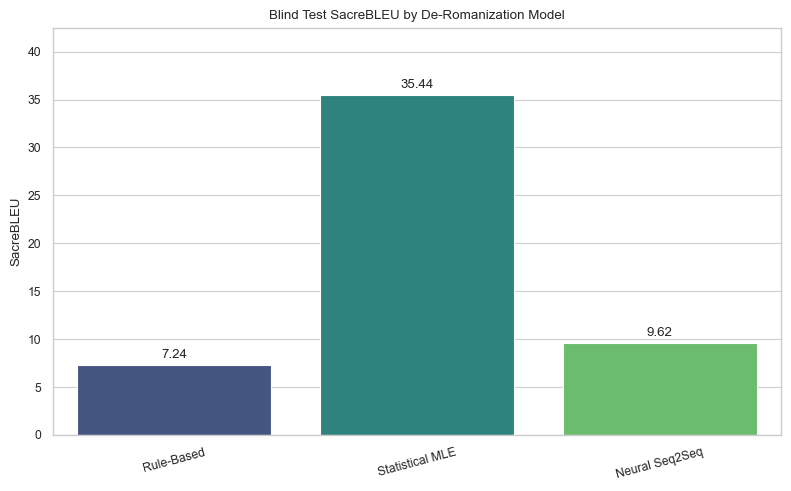

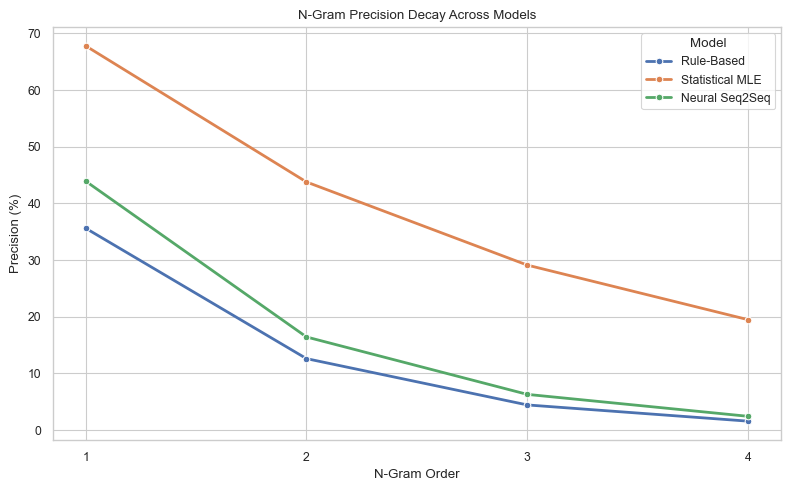

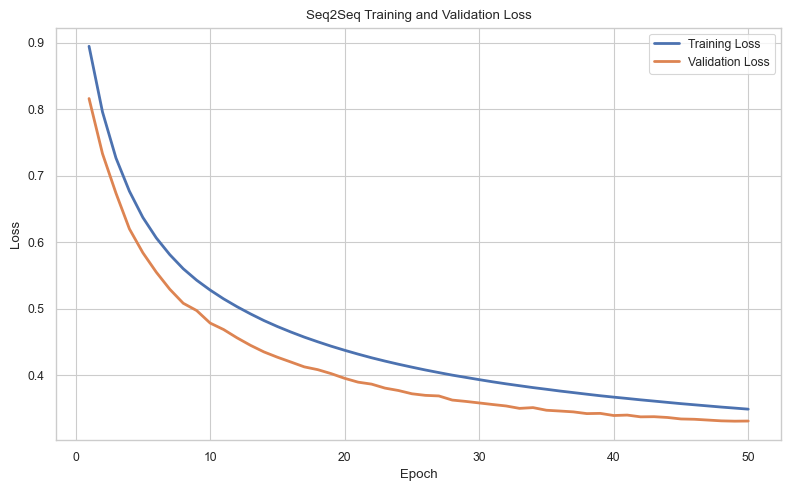

In [22]:
# Benchmark visualizations

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="paper")

# 1. Overall BLEU bar chart
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=results_df, x="Model", y="BLEU", palette="viridis")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Blind Test SacreBLEU by De-Romanization Model")
plt.xlabel("")
plt.ylabel("SacreBLEU")
plt.ylim(0, max(results_df["BLEU"]) * 1.2)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# 2. N-gram precision decay line graph
ngram_df = results_df.melt(
    id_vars="Model",
    value_vars=[
        "1-gram Precision",
        "2-gram Precision",
        "3-gram Precision",
        "4-gram Precision",
    ],
    var_name="N-Gram",
    value_name="Precision"
)

ngram_df["N"] = ngram_df["N-Gram"].str.extract(r"(\d)").astype(int)

plt.figure(figsize=(8, 5))
sns.lineplot(
    data=ngram_df,
    x="N",
    y="Precision",
    hue="Model",
    marker="o",
    linewidth=2
)

plt.title("N-Gram Precision Decay Across Models")
plt.xlabel("N-Gram Order")
plt.ylabel("Precision (%)")
plt.xticks([1, 2, 3, 4])
plt.tight_layout()
plt.show()

# 3. Training loss curve
history_df = pd.DataFrame(history.history)
history_df["Epoch"] = np.arange(1, len(history_df) + 1)

plt.figure(figsize=(8, 5))
sns.lineplot(data=history_df, x="Epoch", y="loss", label="Training Loss", linewidth=2)

if "val_loss" in history_df.columns:
    sns.lineplot(data=history_df, x="Epoch", y="val_loss", label="Validation Loss", linewidth=2)

plt.title("Seq2Seq Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.tight_layout()
plt.show()

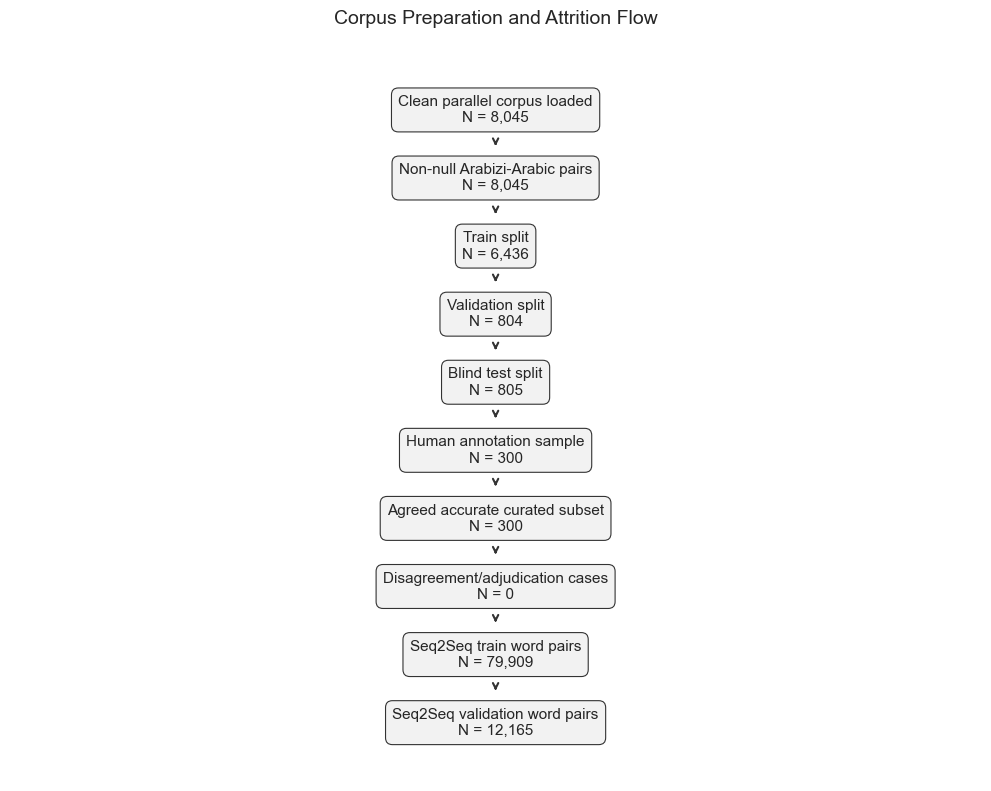

In [23]:
# Corpus attrition diagram

test_pairs, skipped_test_rows = make_word_pairs(test_df)

annotation_n = len(annotation_sample) if "annotation_sample" in globals() else 0
curated_n = len(curated_gold_subset) if "curated_gold_subset" in globals() else 0
disagreement_n = len(disagreement_subset) if "disagreement_subset" in globals() else 0

attrition_steps = [
    ("Clean parallel corpus loaded", len(df)),
    ("Non-null Arabizi-Arabic pairs", len(df.dropna(subset=["text_az", "text_ar"]))),
    ("Train split", len(train_df)),
    ("Validation split", len(val_df)),
    ("Blind test split", len(test_df)),
    ("Human annotation sample", annotation_n),
    ("Agreed accurate curated subset", curated_n),
    ("Disagreement/adjudication cases", disagreement_n),
    ("Seq2Seq train word pairs", len(train_pairs)),
    ("Seq2Seq validation word pairs", len(val_pairs)),
]

fig, ax = plt.subplots(figsize=(10, 8))
ax.axis("off")

y_positions = np.linspace(0.92, 0.08, len(attrition_steps))

for i, ((label, count), y) in enumerate(zip(attrition_steps, y_positions)):
    ax.text(
        0.5,
        y,
        f"{label}\nN = {count:,}",
        ha="center",
        va="center",
        fontsize=11,
        bbox=dict(boxstyle="round,pad=0.45", facecolor="#f2f2f2", edgecolor="#333333")
    )

    if i < len(attrition_steps) - 1:
        ax.annotate(
            "",
            xy=(0.5, y_positions[i + 1] + 0.04),
            xytext=(0.5, y - 0.04),
            arrowprops=dict(arrowstyle="->", linewidth=1.5, color="#333333")
        )

plt.title("Corpus Preparation and Attrition Flow", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

In [27]:
# Aligned linguistic target spotting for clitics and numerals

analysis_df = curated_eval_df.copy() if "curated_eval_df" in globals() and len(curated_eval_df) > 0 else blind_df.copy()
print("Using rows for linguistic analysis:", len(analysis_df))

digit_to_arabic = {
    "2": "ء",
    "3": "ع",
    "5": "خ",
    "7": "ح",
    "8": "غ",
    "9": "ق",
}

clitic_pattern = re.compile(r"^(w|wa|f|fi|b|l|li)[a-z0-9].+", re.IGNORECASE)

arabic_punct = "،؛؟.!?\"'()[]{}:؛,"
arabic_diacritics = re.compile(r"[\u064B-\u065F\u0670\u0640]")

def normalize_ar_token(token):
    token = str(token).strip().strip(arabic_punct)
    token = arabic_diacritics.sub("", token)
    token = token.replace("أ", "ا").replace("إ", "ا").replace("آ", "ا")
    token = token.replace("ى", "ي")
    return token

def align_pred_ref(pred_words, ref_words):
    pred_norm = [normalize_ar_token(w) for w in pred_words]
    ref_norm = [normalize_ar_token(w) for w in ref_words]

    matcher = SequenceMatcher(a=pred_norm, b=ref_norm, autojunk=False)

    aligned_pairs = []

    for tag, i1, i2, j1, j2 in matcher.get_opcodes():
        if tag == "equal":
            for i, j in zip(range(i1, i2), range(j1, j2)):
                aligned_pairs.append({
                    "pred_index": i,
                    "ref_index": j,
                    "pred_word": pred_words[i],
                    "ref_word": ref_words[j],
                    "alignment_operation": "equal",
                })

        elif tag == "replace":
            pred_span = pred_words[i1:i2]
            ref_span = ref_words[j1:j2]

            if len(pred_span) == len(ref_span):
                for offset, (pred_word, ref_word) in enumerate(zip(pred_span, ref_span)):
                    aligned_pairs.append({
                        "pred_index": i1 + offset,
                        "ref_index": j1 + offset,
                        "pred_word": pred_word,
                        "ref_word": ref_word,
                        "alignment_operation": "replace",
                    })
            else:
                aligned_pairs.append({
                    "pred_index": i1,
                    "ref_index": j1,
                    "pred_word": " ".join(pred_span),
                    "ref_word": " ".join(ref_span),
                    "alignment_operation": "replace-span",
                })

        elif tag == "delete":
            for i in range(i1, i2):
                aligned_pairs.append({
                    "pred_index": i,
                    "ref_index": None,
                    "pred_word": pred_words[i],
                    "ref_word": "",
                    "alignment_operation": "delete",
                })

        elif tag == "insert":
            for j in range(j1, j2):
                aligned_pairs.append({
                    "pred_index": None,
                    "ref_index": j,
                    "pred_word": "",
                    "ref_word": ref_words[j],
                    "alignment_operation": "insert",
                })

    return aligned_pairs

spotting_rows = []

for _, row in analysis_df.iterrows():
    az_words = normalize_az(row["text_az"]).split()
    pred_words = clean_ws(row["pred_seq2seq"]).split()
    ref_words = clean_ws(row["gold_ar"]).split()

    aligned_pairs = align_pred_ref(pred_words, ref_words)

    for pair in aligned_pairs:
        pred_index = pair["pred_index"]
        ref_index = pair["ref_index"]

        # Prefer pred index because seq2seq output is word-by-word from Arabizi.
        # Fall back to ref index for inserted gold spans.
        if pred_index is not None and pred_index < len(az_words):
            az_word = az_words[pred_index]
        elif ref_index is not None and ref_index < len(az_words):
            az_word = az_words[ref_index]
        else:
            az_word = ""

        phenomena = []

        if clitic_pattern.match(az_word):
            phenomena.append("Possible clitic attachment")

        digits_found = [d for d in digit_to_arabic if d in az_word]
        if digits_found:
            phenomena.append("Numerical transliteration")

        if not phenomena:
            continue

        expected_letters = [digit_to_arabic[d] for d in digits_found]

        pred_norm = normalize_ar_token(pair["pred_word"])
        ref_norm = normalize_ar_token(pair["ref_word"])

        digit_success_pred = (
            all(letter in pred_norm for letter in expected_letters)
            if expected_letters else np.nan
        )

        digit_success_gold = (
            all(letter in ref_norm for letter in expected_letters)
            if expected_letters else np.nan
        )

        spotting_rows.append({
            "Phenomenon": "; ".join(phenomena),
            "Arabizi Word": az_word,
            "Seq2Seq Prediction": pair["pred_word"],
            "Gold Arabic": pair["ref_word"],
            "Alignment Operation": pair["alignment_operation"],
            "Digit Success in Prediction": digit_success_pred,
            "Digit Present in Gold": digit_success_gold,
            "Full Arabizi Snippet": clean_ws(row["text_az"])[:220],
            "Full Seq2Seq Snippet": clean_ws(row["pred_seq2seq"])[:220],
            "Full Gold Snippet": clean_ws(row["gold_ar"])[:220],
        })

spotting_df = pd.DataFrame(spotting_rows)

display(spotting_df.head(100))

display(
    spotting_df.groupby(["Phenomenon", "Alignment Operation"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

spotting_df.to_csv(
    "linguistic_target_spotting_seq2seq_aligned.csv",
    index=False,
    encoding="utf-8-sig"
)

Using rows for linguistic analysis: 300


,Phenomenon,Arabizi Word,Seq2Seq Prediction,Gold Arabic,Alignment Operation,Digit Success in Prediction,Digit Present in Gold,Full Arabizi Snippet,Full Seq2Seq Snippet,Full Gold Snippet
0,Numerical transliteration,18,18,18,equal,False,False,tlt 18 ynayer 2022 sa3a 17:10 chaf lma3had lwT...,الثلاثة 18 يناير 2222 ساعة 1::01 شاف المعاهد ا...,الثلاثاء 18 يناير 2022، الساعة 17:10، شاف المع...
1,Numerical transliteration,2022,2222,2022،,replace,False,False,tlt 18 ynayer 2022 sa3a 17:10 chaf lma3had lwT...,الثلاثة 18 يناير 2222 ساعة 1::01 شاف المعاهد ا...,الثلاثاء 18 يناير 2022، الساعة 17:10، شاف المع...
2,Numerical transliteration,sa3a,ساعة,الساعة,replace,True,True,tlt 18 ynayer 2022 sa3a 17:10 chaf lma3had lwT...,الثلاثة 18 يناير 2222 ساعة 1::01 شاف المعاهد ا...,الثلاثاء 18 يناير 2022، الساعة 17:10، شاف المع...
3,Numerical transliteration,17:10,1::01,17:10،,replace,False,False,tlt 18 ynayer 2022 sa3a 17:10 chaf lma3had lwT...,الثلاثة 18 يناير 2222 ساعة 1::01 شاف المعاهد ا...,الثلاثاء 18 يناير 2022، الساعة 17:10، شاف المع...
4,Possible clitic attachment; Numerical translit...,lma3had,المعاهد,المعهد,replace,True,True,tlt 18 ynayer 2022 sa3a 17:10 chaf lma3had lwT...,الثلاثة 18 يناير 2222 ساعة 1::01 شاف المعاهد ا...,الثلاثاء 18 يناير 2022، الساعة 17:10، شاف المع...
...,...,...,...,...,...,...,...,...,...,...
95,Numerical transliteration,ys3dna,يساعدنا,يساعدنا,equal,True,True,tlt 18 ynayer 2022 sa3a 17:10 chaf lma3had lwT...,الثلاثة 18 يناير 2222 ساعة 1::01 شاف المعاهد ا...,الثلاثاء 18 يناير 2022، الساعة 17:10، شاف المع...
96,Possible clitic attachment; Numerical translit...,l3alm,العالم,العالم,equal,True,True,tlt 18 ynayer 2022 sa3a 17:10 chaf lma3had lwT...,الثلاثة 18 يناير 2222 ساعة 1::01 شاف المعاهد ا...,الثلاثاء 18 يناير 2022، الساعة 17:10، شاف المع...
97,Possible clitic attachment; Numerical translit...,wn7mo,ونحمو,ونحمو,equal,True,True,tlt 18 ynayer 2022 sa3a 17:10 chaf lma3had lwT...,الثلاثة 18 يناير 2222 ساعة 1::01 شاف المعاهد ا...,الثلاثاء 18 يناير 2022، الساعة 17:10، شاف المع...
98,Possible clitic attachment,lkwarys.,الكوارس.,الكوارث.,replace,NaN,NaN,tlt 18 ynayer 2022 sa3a 17:10 chaf lma3had lwT...,الثلاثة 18 يناير 2222 ساعة 1::01 شاف المعاهد ا...,الثلاثاء 18 يناير 2022، الساعة 17:10، شاف المع...


,Phenomenon,Alignment Operation,Count
8,Possible clitic attachment,replace,7847
6,Possible clitic attachment,equal,7720
1,Numerical transliteration,equal,7313
3,Numerical transliteration,replace,6055
11,Possible clitic attachment; Numerical translit...,equal,5563
13,Possible clitic attachment; Numerical translit...,replace,3209
9,Possible clitic attachment,replace-span,429
4,Numerical transliteration,replace-span,368
14,Possible clitic attachment; Numerical translit...,replace-span,222
7,Possible clitic attachment,insert,148


In [26]:
# Aligned neural error classification
# This avoids falsely penalizing the model for simple word-position shifts.

analysis_df = curated_eval_df.copy() if "curated_eval_df" in globals() and len(curated_eval_df) > 0 else blind_df.copy()
print("Using rows for error classification:", len(analysis_df))

arabic_punct = "،؛؟.!?\"'()[]{}:؛,"
arabic_diacritics = re.compile(r"[\u064B-\u065F\u0670\u0640]")
latin_pattern = re.compile(r"[A-Za-z]")
digit_pattern = re.compile(r"[235789]")

loanword_pattern = re.compile(
    r"(fransa|espanya|police|radio|video|internet|facebook|youtube|sport|club|match|"
    r"minister|parlement|democrati|politic|telephone|whatsapp|instagram)",
    re.IGNORECASE
)

def normalize_ar_token(token):
    token = str(token).strip().strip(arabic_punct)
    token = arabic_diacritics.sub("", token)
    token = token.replace("أ", "ا").replace("إ", "ا").replace("آ", "ا")
    token = token.replace("ى", "ي")
    return token

def classify_aligned_error(az_word, pred_word, ref_word, op_type):
    pred_norm = normalize_ar_token(pred_word)
    ref_norm = normalize_ar_token(ref_word)

    if pred_norm == ref_norm and pred_word != ref_word:
        return "Punctuation/orthographic-only mismatch"

    if op_type == "alignment_shift":
        return "Alignment shift / multi-token mismatch"

    if op_type == "insert":
        return "Model under-generation / missing gold token"

    if op_type == "delete":
        return "Model over-generation / extra predicted token"

    if digit_pattern.search(str(az_word)):
        return "Numerical transliteration error"

    if clitic_pattern.match(str(az_word)):
        return "Clitic attachment / segmentation error"

    if loanword_pattern.search(str(az_word)):
        return "Code-switching or loanword corruption"

    return "Phonetic ambiguity or spelling variant"

aligned_error_rows = []

for _, row in analysis_df.iterrows():
    az_words = normalize_az(row["text_az"]).split()
    pred_words = clean_ws(row["pred_seq2seq"]).split()
    ref_words = clean_ws(row["gold_ar"]).split()

    pred_norm = [normalize_ar_token(w) for w in pred_words]
    ref_norm = [normalize_ar_token(w) for w in ref_words]

    matcher = SequenceMatcher(a=pred_norm, b=ref_norm, autojunk=False)

    for tag, i1, i2, j1, j2 in matcher.get_opcodes():
        if tag == "equal":
            continue

        if tag == "replace":
            pred_span = pred_words[i1:i2]
            ref_span = ref_words[j1:j2]

            if len(pred_span) == len(ref_span):
                for offset, (pred_word, ref_word) in enumerate(zip(pred_span, ref_span)):
                    pred_idx = i1 + offset
                    az_word = az_words[pred_idx] if pred_idx < len(az_words) else ""

                    aligned_error_rows.append({
                        "Arabizi Word": az_word,
                        "Seq2Seq Prediction": pred_word,
                        "Gold Arabic": ref_word,
                        "Alignment Operation": "replace",
                        "Error Type": classify_aligned_error(az_word, pred_word, ref_word, "replace"),
                        "Arabizi Snippet": clean_ws(row["text_az"])[:220],
                        "Seq2Seq Snippet": clean_ws(row["pred_seq2seq"])[:220],
                        "Gold Snippet": clean_ws(row["gold_ar"])[:220],
                    })
            else:
                aligned_error_rows.append({
                    "Arabizi Word": " ".join(az_words[i1:i2]),
                    "Seq2Seq Prediction": " ".join(pred_span),
                    "Gold Arabic": " ".join(ref_span),
                    "Alignment Operation": "replace-span",
                    "Error Type": "Alignment shift / multi-token mismatch",
                    "Arabizi Snippet": clean_ws(row["text_az"])[:220],
                    "Seq2Seq Snippet": clean_ws(row["pred_seq2seq"])[:220],
                    "Gold Snippet": clean_ws(row["gold_ar"])[:220],
                })

        elif tag == "delete":
            for pred_idx in range(i1, i2):
                az_word = az_words[pred_idx] if pred_idx < len(az_words) else ""
                pred_word = pred_words[pred_idx]

                aligned_error_rows.append({
                    "Arabizi Word": az_word,
                    "Seq2Seq Prediction": pred_word,
                    "Gold Arabic": "",
                    "Alignment Operation": "delete",
                    "Error Type": classify_aligned_error(az_word, pred_word, "", "delete"),
                    "Arabizi Snippet": clean_ws(row["text_az"])[:220],
                    "Seq2Seq Snippet": clean_ws(row["pred_seq2seq"])[:220],
                    "Gold Snippet": clean_ws(row["gold_ar"])[:220],
                })

        elif tag == "insert":
            for ref_word in ref_words[j1:j2]:
                aligned_error_rows.append({
                    "Arabizi Word": "",
                    "Seq2Seq Prediction": "",
                    "Gold Arabic": ref_word,
                    "Alignment Operation": "insert",
                    "Error Type": "Model under-generation / missing gold token",
                    "Arabizi Snippet": clean_ws(row["text_az"])[:220],
                    "Seq2Seq Snippet": clean_ws(row["pred_seq2seq"])[:220],
                    "Gold Snippet": clean_ws(row["gold_ar"])[:220],
                })

aligned_errors_df = pd.DataFrame(aligned_error_rows)

reviewable_errors_df = aligned_errors_df[
    aligned_errors_df["Error Type"] != "Alignment shift / multi-token mismatch"
].copy()

error_sample_50 = reviewable_errors_df.sample(
    n=min(50, len(reviewable_errors_df)),
    random_state=42
).reset_index(drop=True)

display(error_sample_50)
display(aligned_errors_df["Error Type"].value_counts().reset_index(name="Count"))

aligned_errors_df.to_csv("seq2seq_aligned_error_typology_all_errors.csv", index=False, encoding="utf-8-sig")
error_sample_50.to_csv("seq2seq_aligned_error_typology_sample_50.csv", index=False, encoding="utf-8-sig")

Using rows for error classification: 300


,Arabizi Word,Seq2Seq Prediction,Gold Arabic,Alignment Operation,Error Type,Arabizi Snippet,Seq2Seq Snippet,Gold Snippet
0,w7a,والحال,واخا,replace,Numerical transliteration error,salam 3likom ana fouziya mn inshadn sma3t lbar...,سلام عليكم كنتمناو فوزية المستوى النشاز المستع...,السلام عليكم، أنا فوزية من إنشادن، سمعت البارح...
1,kita3sb,كيتعابس,كيتعصب،,replace,Numerical transliteration error,salam 3likom ana sa3id mn mdina rbatt kn3aysh ...,سلام عليكم كنتمناو ساعدي المستوى مدينة ربات كن...,السلام عليكم، أنا سعيد من مدينة الرباط، كنعيش ...
2,ltfasil.,التفاصل.,التفاصيل.,replace,Clitic attachment / segmentation error,Ajii lhna sm3twa lkhabar Amir lkwyt mcha lAmri...,أن الحنا سمعتوا الخبار، أمير الكويت مشاء الأمر...,آجي لهنا، سمعتوا الخبر؟ أمير الكويت مشى لأمريك...
3,wbldbt,وبلدبت,وبالضبط,replace,Clitic attachment / segmentation error,# kChf l7a9i9a: tjrbtI m3 mo2ssast dD7a lIs7an...,المستولين كشف الحقيق. تجربتي المواطنين مؤسست ا...,# كشف الحقيقة: تجربتي مع مؤسسة الضحى للإسكان ع...
4,l3asr,العاصر,العصر،,replace,Numerical transliteration error,wach kayn chi jdid fhad lmdina ah sma3t beli g...,واش كاين كيقول جديد المستولين المدينة المستولي...,واش كاين شي جديد فهاد المدينة؟ آه، سمعت باللي ...
5,as7al,أساحل,أشغال,replace,Numerical transliteration error,salam 3likom ana sidi mn mdina taroudant ljami...,سلام عليكم كنتمناو السيدي المستوى مدينة تروضان...,السلام عليكم، أنا سيّدي، من مدينة تارودانت الج...
6,hta,المستورين,حتى,replace,Phonetic ambiguity or spelling variant,sbt 18 abryl 2020 sa3a 5 w nss dyal l3shya. ya...,السبط 18 أبريل 2000 ساعة المواطنين المستولين ن...,السبت 18 أبريل 2020، الساعة 5 ونص ديال العشية....
7,li,التقالب,اللي,replace,Phonetic ambiguity or spelling variant,assalam 3likom ana wiam kntbghi nkteb had lmod...,السلام عليكم كنتمناو ويما كنتبغي نكتب المستولي...,السلام عليكم، أنا وئام، كنبغي نكتب هاد المذكرة...
8,,,ديالو,insert,Model under-generation / missing gold token,slm khoya kidaira m3ak 3likom slm l7md llah ac...,سلم خويا كيدايرة معاك عليكم سلم الحمد الله واش...,السلام عليكم خويا، كيدايرة معاك؟ وعليكم السلام...
9,fach,فالمواطنين,فاش,replace,Clitic attachment / segmentation error,Wach chfti ach kay9olo felespanyole 3la wizara...,واش شفتي واش كيقولو فالإسباني المساملة وزارة د...,واش شفتي آش كايقولو فالإعلام الإسباني على وزار...


,Error Type,Count
0,Phonetic ambiguity or spelling variant,17891
1,Numerical transliteration error,9264
2,Clitic attachment / segmentation error,7847
3,Alignment shift / multi-token mismatch,3261
4,Model under-generation / missing gold token,702
5,Model over-generation / extra predicted token,573
6,Code-switching or loanword corruption,18


In [28]:
# Export aligned neural error sample for human validation

error_review_template = error_sample_50.copy()

error_review_template["human_is_true_error"] = ""
error_review_template["human_error_type"] = ""
error_review_template["human_notes"] = ""

error_review_template["annotation_instructions"] = (
    "human_is_true_error: 1=true model error, "
    "0=acceptable variant/not model error, U=uncertain. "
    "human_error_type options: numerical_transliteration, clitic_segmentation, "
    "phonetic_ambiguity, loanword_codeswitching, alignment_shift, "
    "punctuation_only, gold_reference_issue, source_noise, other."
)

error_review_template.to_csv(
    "seq2seq_aligned_error_typology_sample_50_HUMAN_REVIEW.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Saved human review file:")
print("seq2seq_aligned_error_typology_sample_50_HUMAN_REVIEW.csv")

display(error_review_template.head())

Saved human review file:
seq2seq_aligned_error_typology_sample_50_HUMAN_REVIEW.csv


,Arabizi Word,Seq2Seq Prediction,Gold Arabic,Alignment Operation,Error Type,Arabizi Snippet,Seq2Seq Snippet,Gold Snippet,human_is_true_error,human_error_type,human_notes,annotation_instructions
0,w7a,والحال,واخا,replace,Numerical transliteration error,salam 3likom ana fouziya mn inshadn sma3t lbar...,سلام عليكم كنتمناو فوزية المستوى النشاز المستع...,السلام عليكم، أنا فوزية من إنشادن، سمعت البارح...,,,,"human_is_true_error: 1=true model error, 0=acc..."
1,kita3sb,كيتعابس,كيتعصب،,replace,Numerical transliteration error,salam 3likom ana sa3id mn mdina rbatt kn3aysh ...,سلام عليكم كنتمناو ساعدي المستوى مدينة ربات كن...,السلام عليكم، أنا سعيد من مدينة الرباط، كنعيش ...,,,,"human_is_true_error: 1=true model error, 0=acc..."
2,ltfasil.,التفاصل.,التفاصيل.,replace,Clitic attachment / segmentation error,Ajii lhna sm3twa lkhabar Amir lkwyt mcha lAmri...,أن الحنا سمعتوا الخبار، أمير الكويت مشاء الأمر...,آجي لهنا، سمعتوا الخبر؟ أمير الكويت مشى لأمريك...,,,,"human_is_true_error: 1=true model error, 0=acc..."
3,wbldbt,وبلدبت,وبالضبط,replace,Clitic attachment / segmentation error,# kChf l7a9i9a: tjrbtI m3 mo2ssast dD7a lIs7an...,المستولين كشف الحقيق. تجربتي المواطنين مؤسست ا...,# كشف الحقيقة: تجربتي مع مؤسسة الضحى للإسكان ع...,,,,"human_is_true_error: 1=true model error, 0=acc..."
4,l3asr,العاصر,العصر،,replace,Numerical transliteration error,wach kayn chi jdid fhad lmdina ah sma3t beli g...,واش كاين كيقول جديد المستولين المدينة المستولي...,واش كاين شي جديد فهاد المدينة؟ آه، سمعت باللي ...,,,,"human_is_true_error: 1=true model error, 0=acc..."


,Arabizi Word,Seq2Seq Prediction,Gold Arabic,Alignment Operation,Error Type,Arabizi Snippet,Seq2Seq Snippet,Gold Snippet,human_is_true_error,human_error_type,human_notes,annotation_instructions,human_true_error_label,parsed_error_labels,human_error_type_primary,human_secondary_factors,human_error_type_clean
0,w7a,والحال,واخا,replace,Numerical transliteration error,salam 3likom ana fouziya mn inshadn sma3t lbar...,سلام عليكم كنتمناو فوزية المستوى النشاز المستع...,السلام عليكم، أنا فوزية من إنشادن، سمعت البارح...,acceptable variant,source_noise,Source token 'w7a' is noisy or abbreviated; ke...,"human_is_true_error: 1=true model error, 0=acc...",Acceptable variant / not model error,[source_noise],source_noise,,source_noise
1,kita3sb,كيتعابس,كيتعصب،,replace,Numerical transliteration error,salam 3likom ana sa3id mn mdina rbatt kn3aysh ...,سلام عليكم كنتمناو ساعدي المستوى مدينة ربات كن...,السلام عليكم، أنا سعيد من مدينة الرباط، كنعيش ...,true model error,"phonetic_ambiguity, source_noise",Near-form spelling/phonetic mismatch for sourc...,"human_is_true_error: 1=true model error, 0=acc...",True model error,"[phonetic_ambiguity, source_noise]",phonetic_ambiguity,source_noise,phonetic_ambiguity
2,ltfasil.,التفاصل.,التفاصيل.,replace,Clitic attachment / segmentation error,Ajii lhna sm3twa lkhabar Amir lkwyt mcha lAmri...,أن الحنا سمعتوا الخبار، أمير الكويت مشاء الأمر...,آجي لهنا، سمعتوا الخبر؟ أمير الكويت مشى لأمريك...,true model error,phonetic_ambiguity,Near-form spelling/phonetic mismatch for sourc...,"human_is_true_error: 1=true model error, 0=acc...",True model error,[phonetic_ambiguity],phonetic_ambiguity,,phonetic_ambiguity
3,wbldbt,وبلدبت,وبالضبط,replace,Clitic attachment / segmentation error,# kChf l7a9i9a: tjrbtI m3 mo2ssast dD7a lIs7an...,المستولين كشف الحقيق. تجربتي المواطنين مؤسست ا...,# كشف الحقيقة: تجربتي مع مؤسسة الضحى للإسكان ع...,true model error,"phonetic_ambiguity, source_noise",Near-form spelling/phonetic mismatch for sourc...,"human_is_true_error: 1=true model error, 0=acc...",True model error,"[phonetic_ambiguity, source_noise]",phonetic_ambiguity,source_noise,phonetic_ambiguity
4,l3asr,العاصر,العصر،,replace,Numerical transliteration error,wach kayn chi jdid fhad lmdina ah sma3t beli g...,واش كاين كيقول جديد المستولين المدينة المستولي...,واش كاين شي جديد فهاد المدينة؟ آه، سمعت باللي ...,true model error,phonetic_ambiguity,Near-form spelling/phonetic mismatch for sourc...,"human_is_true_error: 1=true model error, 0=acc...",True model error,[phonetic_ambiguity],phonetic_ambiguity,,phonetic_ambiguity


,Human Judgment,Count
0,True model error,42
1,Acceptable variant / not model error,6
2,Uncertain,2


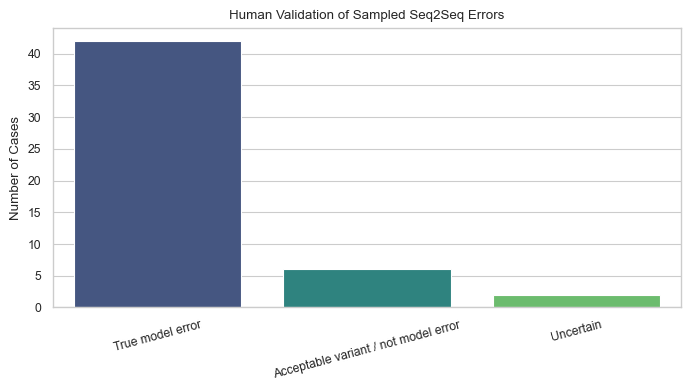

,Primary Human Error Type,Count
0,lexical_substitution,22
1,phonetic_ambiguity,19
2,source_noise,1


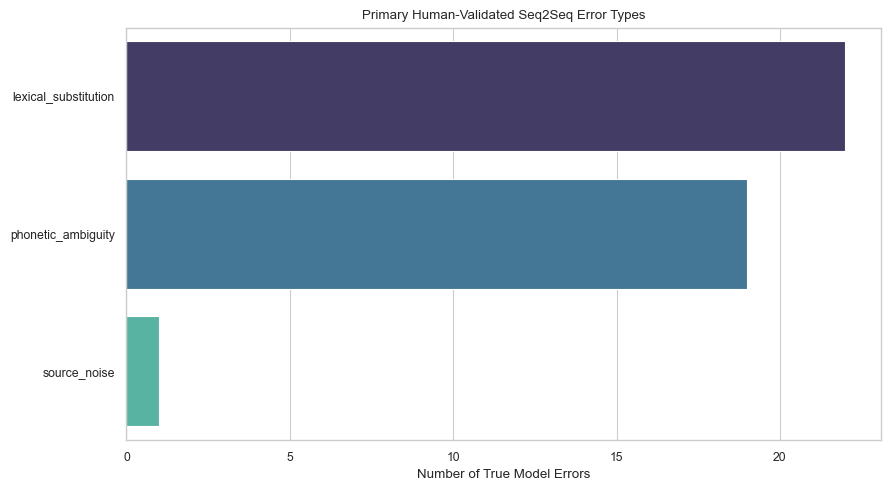

In [33]:
# Load human-validated neural error review and visualize single-primary-label typology

human_error_review = pd.read_csv(
    "seq2seq_aligned_error_typology_sample_50_HUMAN_REVIEW_completed.csv",
    encoding="utf-8-sig"
)

def normalize_true_error_label(x):
    x = str(x).strip().lower()

    if x in {"true model error", "1", "yes", "y", "true"}:
        return "True model error"

    if x in {"acceptable variant", "0", "no", "n", "acceptable", "not error", "not model error"}:
        return "Acceptable variant / not model error"

    if x in {"uncertain", "u", "unsure", "?"}:
        return "Uncertain"

    return "Unlabeled"

def parse_error_labels(x):
    x = str(x).strip().lower()

    if x in {"", "nan", "none"}:
        return []

    labels = re.split(r"[,;/|]+", x)
    labels = [label.strip().replace(" ", "_") for label in labels if label.strip()]

    aliases = {
        "code-switching": "loanword_codeswitching",
        "codeswitching": "loanword_codeswitching",
        "loanword": "loanword_codeswitching",
        "not_error": "no_error",
        "acceptable_variant": "no_error",
        "not_model_error": "no_error",
    }

    return [aliases.get(label, label) for label in labels]

primary_priority = [
    "lexical_substitution",
    "phonetic_ambiguity",
    "numerical_transliteration",
    "clitic_segmentation",
    "loanword_codeswitching",
    "punctuation_only",
    "alignment_shift",
    "source_noise",
    "gold_reference_issue",
    "no_error",
    "other",
]

def choose_primary_label(labels):
    if not labels:
        return "unlabeled"

    for label in primary_priority:
        if label in labels:
            return label

    return labels[0]

human_error_review["human_true_error_label"] = human_error_review[
    "human_is_true_error"
].apply(normalize_true_error_label)

human_error_review["parsed_error_labels"] = human_error_review[
    "human_error_type"
].apply(parse_error_labels)

human_error_review["human_error_type_primary"] = human_error_review[
    "parsed_error_labels"
].apply(choose_primary_label)

human_error_review["human_secondary_factors"] = human_error_review.apply(
    lambda row: ", ".join(
        label for label in row["parsed_error_labels"]
        if label != row["human_error_type_primary"]
    ),
    axis=1
)

# Keep this for compatibility with earlier plotting code
human_error_review["human_error_type_clean"] = human_error_review["human_error_type_primary"]

display(human_error_review.head())

# Human judgment summary
true_error_summary = (
    human_error_review["human_true_error_label"]
    .value_counts()
    .reset_index()
)

true_error_summary.columns = ["Human Judgment", "Count"]
display(true_error_summary)

plt.figure(figsize=(7, 4))
sns.barplot(
    data=true_error_summary,
    x="Human Judgment",
    y="Count",
    hue="Human Judgment",
    palette="viridis",
    legend=False
)

plt.title("Human Validation of Sampled Seq2Seq Errors")
plt.xlabel("")
plt.ylabel("Number of Cases")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Primary error typology: only true model errors
true_model_errors = human_error_review[
    human_error_review["human_true_error_label"] == "True model error"
].copy()

error_type_summary = (
    true_model_errors["human_error_type_primary"]
    .value_counts()
    .reset_index()
)

error_type_summary.columns = ["Primary Human Error Type", "Count"]
display(error_type_summary)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=error_type_summary,
    y="Primary Human Error Type",
    x="Count",
    hue="Primary Human Error Type",
    palette="mako",
    legend=False
)

plt.title("Primary Human-Validated Seq2Seq Error Types")
plt.xlabel("Number of True Model Errors")
plt.ylabel("")
plt.tight_layout()
plt.show()

human_error_review.to_csv(
    "seq2seq_human_validated_error_review_primary_labels.csv",
    index=False,
    encoding="utf-8-sig"
)

true_error_summary.to_csv(
    "seq2seq_human_true_error_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

error_type_summary.to_csv(
    "seq2seq_human_primary_error_type_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

In [34]:
# Final reproducibility summary for paper/reporting

summary_items = {
    "Train rows": len(train_df),
    "Validation rows": len(val_df),
    "Blind test rows": len(test_df),
    "Human annotation sample size": len(annotation_sample) if "annotation_sample" in globals() else "Not available",
    "Curated gold subset rows": len(curated_gold_subset) if "curated_gold_subset" in globals() else "Not available",
    "Seq2Seq train word pairs": len(train_pairs) if "train_pairs" in globals() else "Not available",
    "Seq2Seq validation word pairs": len(val_pairs) if "val_pairs" in globals() else "Not available",
    "Skipped train rows for Seq2Seq word alignment": skipped_train_rows if "skipped_train_rows" in globals() else "Not available",
    "Skipped validation rows for Seq2Seq word alignment": skipped_val_rows if "skipped_val_rows" in globals() else "Not available",
    "Max encoder word length": max_encoder_seq_length if "max_encoder_seq_length" in globals() else "Not available",
    "Max decoder word length": max_decoder_seq_length if "max_decoder_seq_length" in globals() else "Not available",
    "Encoder character vocabulary size": num_encoder_tokens if "num_encoder_tokens" in globals() else "Not available",
    "Decoder character vocabulary size": num_decoder_tokens if "num_decoder_tokens" in globals() else "Not available",
    "Evaluation metrics": "SacreBLEU, n-gram precision decay, position-wise exact word match, qualitative human error typology",
}

reproducibility_summary_df = pd.DataFrame(
    list(summary_items.items()),
    columns=["Item", "Value"]
)

display(reproducibility_summary_df)

reproducibility_summary_df.to_csv(
    "reproducibility_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Saved: reproducibility_summary.csv")

,Item,Value
0,Train rows,6436
1,Validation rows,804
2,Blind test rows,805
3,Human annotation sample size,300
4,Curated gold subset rows,300
5,Seq2Seq train word pairs,79909
6,Seq2Seq validation word pairs,12165
7,Skipped train rows for Seq2Seq word alignment,5744
8,Skipped validation rows for Seq2Seq word align...,713
9,Max encoder word length,23


Saved: reproducibility_summary.csv
